# Cored Isothermal Sphere

This notebook demonstrates the implementation of the **Cored Isothermal Sphere (CIS)** lens model in `gwlens\lens\cis.py` and demonstrates the use of its definitions.

The CIS profile extends the Singular Isothermal Sphere (SIS) by introducing a finite core radius, thereby removing the central density singularity while retaining an isothermal profile at large radii. This is designed with a view to model lensing by globular clusters.

The implementation evaluates the diffraction integral numerically and constructs interpolation tables for efficient evaluation of the complex amplification factor. It is also shown that the CIS approaches the SIS profile as $x_c \to 0$.

### Dimensionless Lensing Potential

The dimensionless lensing potential for the CIS profile is

$$
\psi(x)
=
\psi_0
\left[
\sqrt{x^2+x_c^2}
+
x_c
\ln\!\left(
\frac{2x_c}
{\sqrt{x^2+x_c^2}+x_c}
\right)
\right]
$$

where,

- $x$ is the dimensionless image position,
- $x_c$ is the dimensionless core radius,
- $\psi_0$ is the dimensionless lensing strength.

The SIS potential is recovered in the limit

$$
\lim_{x_c\rightarrow0}
\psi(x)
=
\psi_0 x.
$$

Here, $\psi_0=1$ is used.

### Imports

In [ ]:
from gwlens.lens import cis
import numpy as np
import matplotlib.pyplot as plt
from gwlens.tools import plotting
from astropy import units as u
plotting.apply_figure_style()

import matplotlib as mpl
mpl.rcParams["text.usetex"] = False #added because I don't have texlive installed on my WSL machine

In [ ]:
help(cis) #lists comments and docstrings for the cis lens module

Help on module gwlens.lens.cis in gwlens.lens:

NAME
    gwlens.lens.cis

FUNCTIONS
    CISAmplification(w, y, amp, core)
    
    compute_cis_lens_grid(w_values, y_values, amp, core, hdf5_filename, num_processes=None)
        Computes the Point(w, y) complex amplification factor over a grid
        and stores the result in an HDF5 file.
        
        Parameters:
        - w_values (1D np.array): dimensionless frequency array
        - y_values (1D np.array): impact parameter array
        - hdf5_filename (str): path to output HDF5 file
        - num_processes (int or None): number of CPU cores to use (default: all)
    
    ddfunc_cis(x, w, y, amp, core)
        Uses the exact identity: J1'(z) = J0(z) - J1(z)/z
        which is equivalent to: J1'(z) = (J0(z) - J2(z))/2 via the Bessel recurrence: J2(z) = 2 J1(z)/z - J0(z).
    
    dfunc_cis(x, w, y, amp, core)
    
    func2_cis(x, w, y, amp, core)
    
    func_cis(x, w, y, amp, core)
    
    psi_cis(x, amp, core)

DATA
    eps =

### Wave-Optics Amplification

The amplification factor is obtained by evaluating the diffraction integral

$$
F(w,y)
=
-iw
e^{\frac{i}{2}wy^2}
\int_0^\infty
J_0\!\left(wy\sqrt{2x}\right)
\exp\!\left[
iw
\left(
x-\psi(\sqrt{2x})
\right)
\right]
dx.
$$

where

- $w$ is the dimensionless frequency,
- $y$ is the dimensionless impact parameter,
- $J_0$ denotes the Bessel function of the first kind.



The diffraction integral is evaluated using arbitrary-precision arithmetic (`mpmath`) with adaptive quadrature. To improve convergence of the oscillatory integral, integration-by-parts tail corrections are also included.


## Interpolation Tables

The complex amplification factor

$$
F(w,y)
=
F_{\rm R}(w,y)
+
iF_{\rm I}(w,y)
$$

is computed on a two-dimensional grid in $(w,y)$ and stored in an hdf5 interpolation table.

The table enables rapid evaluation of the amplification factor without recomputing the diffraction integral for each query. We now use the hdf5 data to plot $|F|$, first for a single impact parameter, then for multiple, on the same plot.

(1000,)
(3,)
(1000, 3, 2)


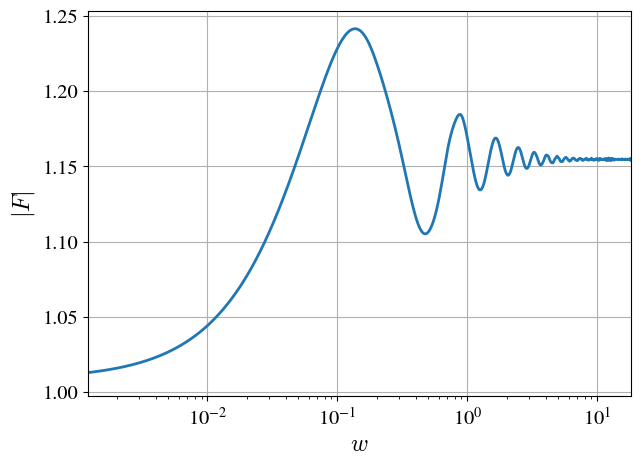

In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

file = "/home/ansalk/GWLENS/outdir/interpolation/result_cis.hdf5"

with h5py.File(file, "r") as f:
    w_values = f["w_values"][:]
    y_values = f["y_values"][:]
    data = f["results"][:]

print(w_values.shape)      # (1000,)
print(y_values.shape)      # (1,)
print(data.shape)          # (1000,1,2)

# Extract the only y slice
real = data[:, 0, 0]
imag = data[:, 0, 1]

# 1D interpolation
real_interp = interp1d(
    w_values,
    real,
    kind="cubic",
    bounds_error=False,
    fill_value="extrapolate"
)

imag_interp = interp1d(
    w_values,
    imag,
    kind="cubic",
    bounds_error=False,
    fill_value="extrapolate"
)

# Evaluate
w = np.logspace(np.log10(w_values[0]), np.log10(w_values[-1]), 1000)

F = real_interp(w) + 1j*imag_interp(w)

plt.figure(figsize=(7,5))
plt.plot(w, np.abs(F), lw=2)
plt.xscale("log")
plt.xlabel(r"$w$")
plt.xlim([w[180], w[-125]])
plt.ylabel(r"$|F|$")
plt.grid(True)
plt.show()

In [57]:
from gwlens.lens.cis import CISAmplification

w = 10
y = y_values[0]

F_exact = CISAmplification(w, y, 1.0, 0.1)

print("Exact :", F_exact)

F_interp = real_interp(w) + 1j*imag_interp(w)

print("Interp:", F_interp)

Exact : (0.96636245909689179539245508418453076253955718191708 - 0.63159461451459225189663135182967176235717261750777j)
Interp: (0.9663508999272009-0.6315514264195807j)


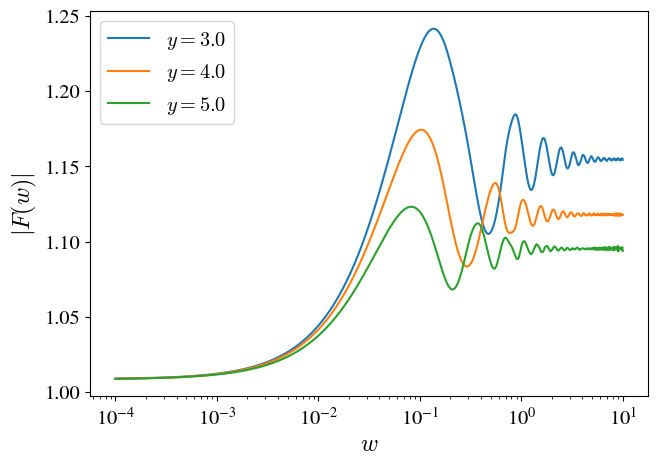

In [58]:
import numpy as np
import h5py
from scipy.interpolate import RectBivariateSpline
import matplotlib.pyplot as plt

from gwlens.tools import plotting

plotting.apply_figure_style()
import matplotlib as mpl

mpl.rcParams["text.usetex"] = False
# --------------------------------------------------
# Load interpolation table
# --------------------------------------------------

file = "/home/ansalk/GWLENS/outdir/interpolation/result_cis.hdf5"

with h5py.File(file, "r") as f:
    w_values = f["w_values"][:]
    y_values = f["y_values"][:]
    data = f["results"][:]

real_data = data[:, :, 0]
imag_data = data[:, :, 1]

real_spline = RectBivariateSpline(
    w_values,
    y_values,
    real_data,
    kx=3,
    ky=2
)

imag_spline = RectBivariateSpline(
    w_values,
    y_values,
    imag_data,
    kx=3,
    ky=2
)

# --------------------------------------------------
# Evaluate interpolation
# --------------------------------------------------

w = np.logspace(-4,1,1000)

for y in [3.0, 4.0, 5.0]:

    F = (
        real_spline(w, y)[:, 0]
        + 1j * imag_spline(w, y)[:, 0]
    )

    plt.plot(
        w,
        np.abs(F),
        label=fr"$y={y}$"
    )

plt.xlabel(r"$w$")
plt.ylabel(r"$|F(w)|$")
plt.xscale("log")
plt.legend()

plt.show()

### Using the defined functions to plot $|F|$

Check `gwlens\lens\cis.py` for the definitions used here.

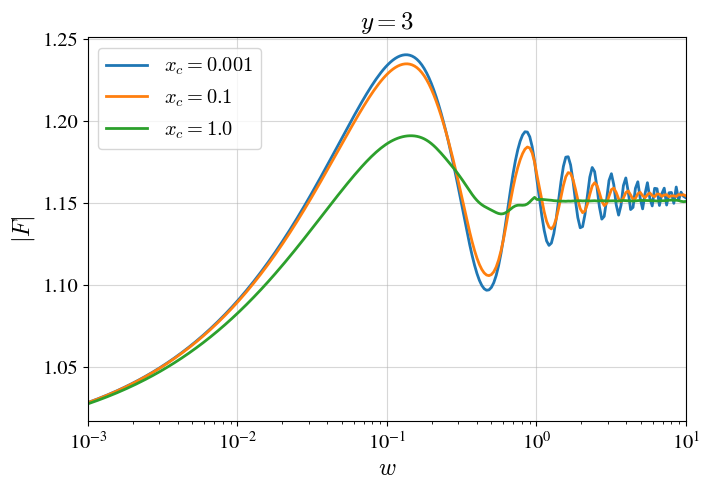

In [60]:
import numpy as np
import matplotlib.pyplot as plt
from gwlens.tools import plotting

plotting.apply_figure_style()
import matplotlib as mpl

mpl.rcParams["text.usetex"] = False

psi0 = 1.0
y = 3.0
core_radii = [0.001, 0.1, 1.0]

w = np.logspace(-3, 1, 250)


for rc in core_radii:

    F = np.empty(len(w), dtype=complex)

    for i, wi in enumerate(w):
        F[i] = complex(cis.CISAmplification(wi, y, psi0, rc))

    # -----------------------
    # Magnitude
    # -----------------------
    plt.plot(
        w,
        np.abs(F),
        lw=2,
        label=fr"$x_c={rc}$"
    )

# ===========================
# Formatting
# ===========================

plt.xscale("log")
plt.xlim(1e-3, 1e1)
plt.ylabel(r"$|F|$")
plt.xlabel(r"$w$")

plt.title(r"$y=3$", fontsize=18)

plt.grid(alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Let's use the SIS definition `compute_F` to find and compare $|F|$

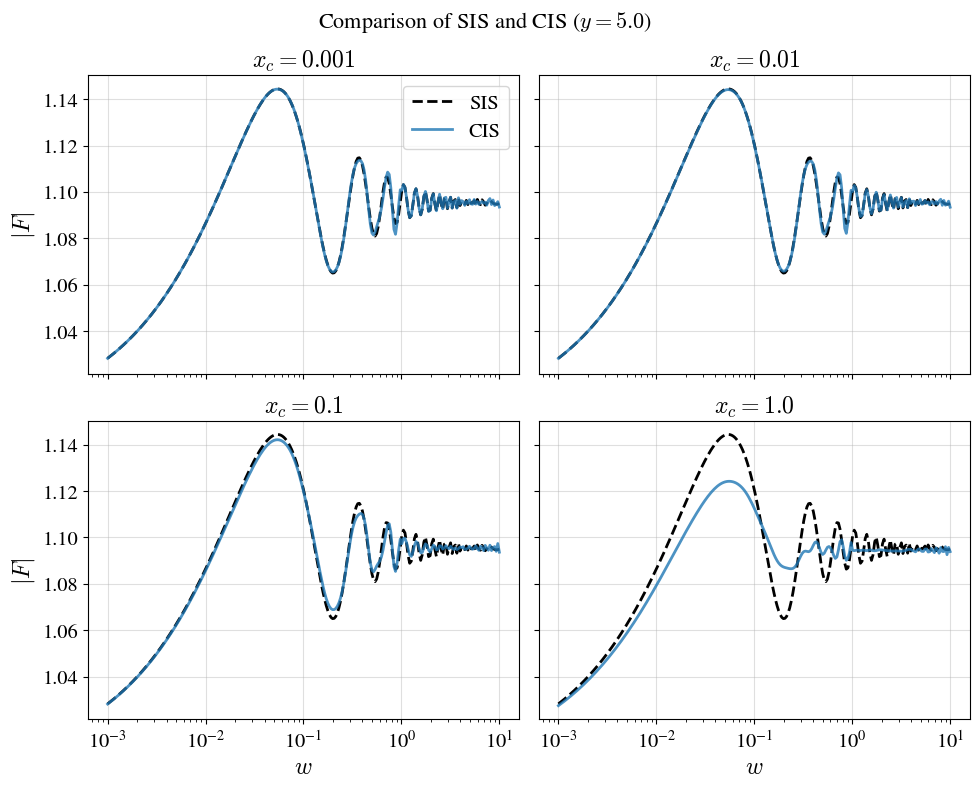

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from gwlens.lens import sis, cis
from gwlens.tools import plotting
from gwlens.lens.sis import calculate_F

plotting.apply_figure_style()
mpl.rcParams["text.usetex"] = False

# -----------------------------
# Lens parameters
# -----------------------------
psi0 = 1.0
y = 5.0

core_radii = [0.001, 0.01, 0.1, 1.0]

w = np.logspace(-3, 1, 250)

# -----------------------------
# SIS
# -----------------------------
sis_lens = sis.SIS()

F_sis = np.array([
    complex(calculate_F(wi, y, n_lim=200))
    for wi in w
])

# -----------------------------
# Figure
# -----------------------------
fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 8),
    sharex=True,
    sharey=True
)

axes = axes.ravel()

for ax, rc in zip(axes, core_radii):

    F_cis = np.empty(len(w), dtype=complex)

    for i, wi in enumerate(w):
        F_cis[i] = complex(
            cis.CISAmplification(
                wi,
                y,
                psi0,
                rc
            )
        )

    ax.plot(
        w,
        np.abs(F_sis),
        "k--",
        lw=2,
        label="SIS"
    )

    ax.plot(
        w,
        np.abs(F_cis),
        color="tab:blue",
        lw=2, alpha=0.8,
        label="CIS"
    )

    ax.set_xscale("log")
    ax.set_title(rf"$x_c={rc}$")
    ax.grid(alpha=0.4)

axes[0].set_ylabel(r"$|F|$")
axes[2].set_ylabel(r"$|F|$")

axes[2].set_xlabel(r"$w$")
axes[3].set_xlabel(r"$w$")

axes[0].legend()

plt.suptitle(rf"Comparison of SIS and CIS ($y={y}$)", fontsize=16)

plt.tight_layout()
plt.show()

### Comparison with the SIS Solution

The above comparison illustrates the convergence of the CIS amplification factor towards the analytical SIS wave-optics solution for progressively smaller core radii.

As expected,

- very small core radii are almost indistinguishable from the SIS solution,
- increasing the core radius suppresses diffraction fringes

Defining the SIS just like the CIS, albeit with the changed potential pprovides another check:

In [ ]:

from mpmath import exp, sqrt
import numpy as np
from mpmath import quad
from mpmath import besselj



def psi_sis(x, amp):
    return amp * x


def func_sis(x, w, y, amp):
    u = sqrt(2*x)
    z = w*y*u

    return besselj(0, z) * exp(-1j*w*psi_sis(u, amp))

def func2_sis(x, w, y, amp):
    return func_sis(x, w, y, amp) * exp(1j*w*x)

def dfunc_sis(x, w, y, amp):

    u = sqrt(2*x)

    dpsi_dx = amp/u

    J1 = besselj(1, w*y*u)

    prefactor = -w*y/u

    return (
        prefactor*J1*exp(-1j*w*psi_sis(u, amp))
        -1j*w*dpsi_dx*func_sis(x,w,y,amp)
    )
    
def ddfunc_sis(x,w,y,amp):

    u = sqrt(2*x)

    dpsi_dx = amp/u
    d2psi_dx2 = -amp/u**3

    A = -1j*w*dpsi_dx
    Aprime = -1j*w*d2psi_dx2

    z = w*y*u

    J1 = besselj(1,z)

    f = func_sis(x,w,y,amp)
    df = dfunc_sis(x,w,y,amp)

    extra_term = 2*w*y/u**3 * J1 * exp(-1j*w*psi_sis(u,amp))

    coeff_f = Aprime - A**2 - (w*y)**2/u**2

    return coeff_f*f + 2*A*df + extra_term

def SISAmplification(w,y,amp):

    a = 1e-5

    if w < 1:
        b = 100/w
    elif w < 500:
        b = 1000/w
    else:
        b = 10000/w

    zz = quad(
        lambda x: func2_sis(x,w,y,amp),
        [a,b],
        error=True,
        maxdegree=10
    )

    zz_val = zz[0]

    tail = (
        -func_sis(b,w,y,amp)/(1j*w)*exp(1j*w*b)
        -dfunc_sis(b,w,y,amp)/(w**2)*exp(1j*w*b)
        +ddfunc_sis(b,w,y,amp)/(1j*w**3)*exp(1j*w*b)
    )

    zz_val += tail

    return -1j*w*exp(0.5j*w*y**2)*zz_val


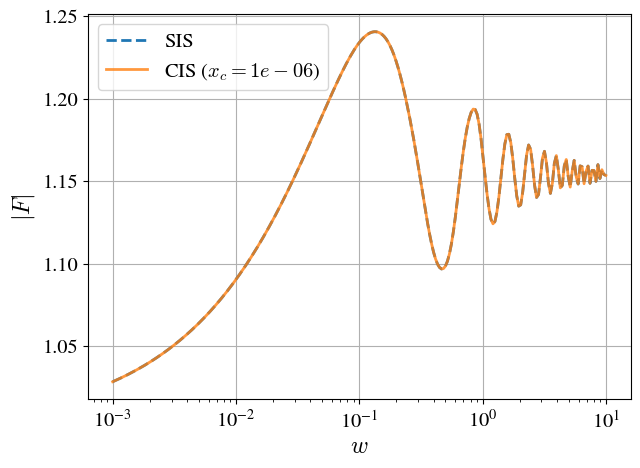

In [ ]:
core = 1e-6

F_cis = np.array([
    complex(cis.CISAmplification(wi, y, 1.0, core))
    for wi in w
])

F_sis = np.array([
    complex(SISAmplification(wi, y, 1.0))
    for wi in w
])

plt.figure(figsize=(7,5))

plt.plot(w, np.abs(F_sis), '--', lw=2, label="SIS")
plt.plot(w, np.abs(F_cis), lw=2, alpha=0.8, label=rf"CIS ($x_c={core}$)")

plt.xscale("log")
plt.xlabel(r"$w$")
plt.ylabel(r"$|F|$")
plt.legend()
plt.grid(True)
plt.show()